In [81]:
%sx basis_tools convert basisset_JMRUI challenge_basis --remove_reference --hlsvd
%sx basis_tools conj challenge_basis challenge_basis
%sx rm challenge_basis/Ace.json

[]

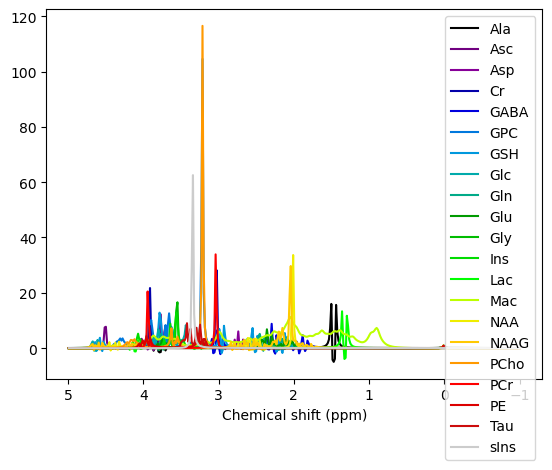

In [158]:
from fsl_mrs.utils import mrs_io
import fsl_mrs.utils.synthetic as synth
import matplotlib.pyplot as plt
import numpy as np
basis = mrs_io.read_basis('challenge_basis')
_ = basis.plot(ppmlim=(-1,5))

{'Ala': 0.6, 'Asc': 1.2, 'Asp': 2.4, 'Cr': 4.87, 'GABA': 1.2, 'GPC': 0.74, 'GSH': 1.2, 'Glc': 1.2, 'Gln': 3.37, 'Glu': 12.41, 'Gly': 1.2, 'Ins': 7.72, 'Lac': 0.6, 'Mac': 5, 'NAA': 13.8, 'NAAG': 1.2, 'PCho': 0.85, 'PCr': 4.87, 'PE': 1.8, 'Tau': 1.8, 'sIns': 0.3}
24.50526785092426
9.70864306620156


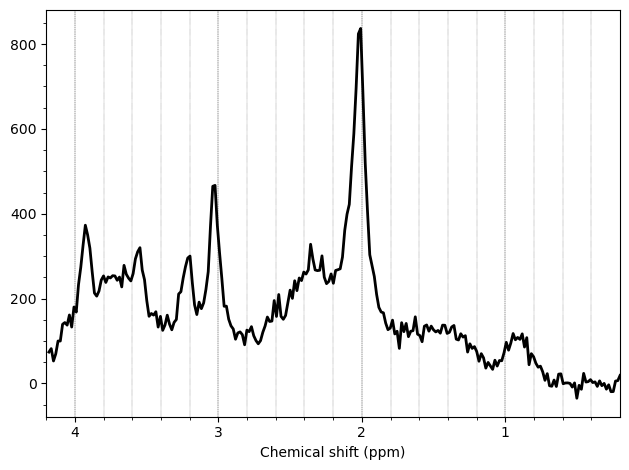

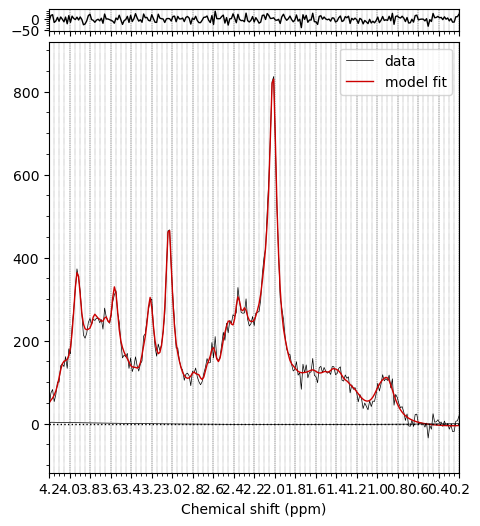

In [178]:

synth_spec, mrs, conc = synth.syntheticFromBasisFile(
    'challenge_basis',
    points=1024,
    bandwidth=2000,
    broadening=(23.0, 0.0),
    noisecovariance=[[200]],
    concentrations={'Mac':5})
mrs.FID = synth_spec
_ = mrs.plot()
res = mrs.fit()
fit_fig = res.plot(mrs)
fit_fig.set_size_inches(9/2, 10/2)
SNR, FWHM = res.getQCParams()
original_concs = dict(zip(mrs.names, conc))
print(original_concs)
print(SNR['SNR_NAA'])
print(FWHM['fwhm_NAA'])


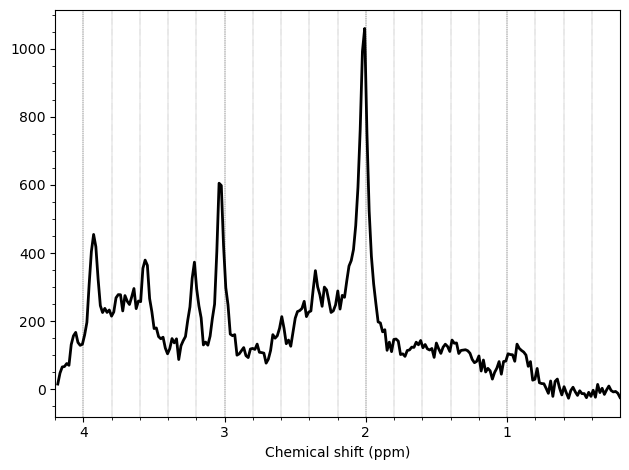

In [164]:
def single_spectrum(concs_in, noise=200, lw=(14.0, 0.0)):
    synth_spec, mrs, _ = synth.syntheticFromBasisFile(
        'challenge_basis',
        points=1024,
        bandwidth=2000,
        broadening=lw,
        noisecovariance=[[noise]],
        concentrations=concs_in)
    mrs.FID = synth_spec
    return mrs

single_spectrum(original_concs).plot()

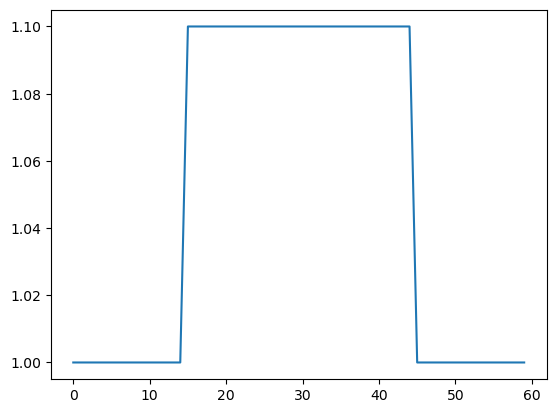

In [45]:
tr = 2
ta = 120
stim_duration = 60
stim_start = 30

nt = int(ta / tr)
stim_steps = int(stim_duration / tr)
stim_start_step = int(stim_start / tr)

def boxcar(delta):
    response = np.ones(nt)
    response[stim_start_step:(stim_start_step+stim_steps)] += delta
    return response

plt.plot(boxcar(0.1))
plt.show()

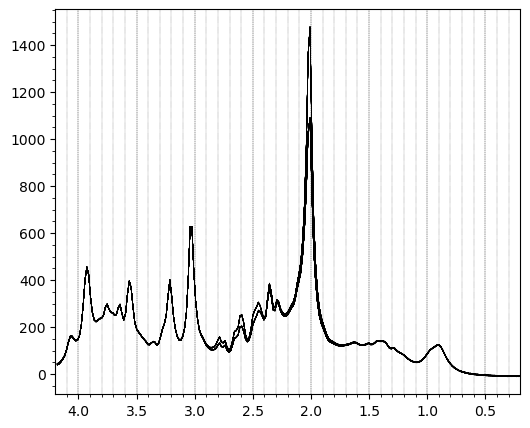

In [46]:
def gen_timeseries(metabolite, delta, base_concs, **kwargs):
    mrs_list = []
    design = boxcar(delta)
    concs_in = base_concs.copy()
    for factor in design:
        concs_in[metabolite] = base_concs[metabolite] * factor
        mrs_list.append(single_spectrum(concs_in, **kwargs))
    return mrs_list

naa_list = gen_timeseries('NAA', 0.5, original_concs, noise=1)

from fsl_mrs.utils.plotting import plot_spectra
list_fig = plot_spectra(naa_list, plot_avg=False, ppmlim=(0.2, 4.2))
list_fig.set_size_inches(6, 5)

/Users/wclarke/opt/miniconda3/envs/fsl_mrs/lib/python3.8/site-packages/nilearn/datasets/__init__.py:93: FutureWarning:

Fetchers from the nilearn.datasets module will be updated in version 0.9 to return python strings instead of bytes and Pandas dataframes instead of Numpy arrays.

/Users/wclarke/opt/miniconda3/envs/fsl_mrs/lib/python3.8/site-packages/nilearn/glm/__init__.py:55: FutureWarning:

The nilearn.glm module is experimental. It may change in any future release of Nilearn.



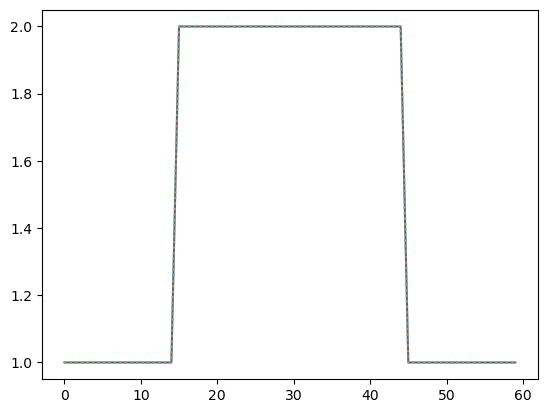

In [47]:
from fsl_mrs import dynamic as dyn
import pandas as pd
from nilearn.glm.first_level import make_first_level_design_matrix

Fitargs = {
    'baseline_order': 0,
    'ppmlim': (0.2, 4.2),
    'model': 'lorentzian'}

frame_times = np.arange(60) * tr
conditions = ['STIM', ]
duration = [stim_duration, ]
onsets = [stim_start, ]  # Start time of each stimulation block.
events = pd.DataFrame({'trial_type': conditions,
                       'onset': onsets,
                       'duration': duration})

design_matrix = make_first_level_design_matrix(
    frame_times,
    events,
    drift_model='polynomial',
    drift_order=0,
    hrf_model='fir'
)


plt.plot(design_matrix.sum(axis=1).to_numpy())
plt.plot(boxcar(1),':')
plt.show()

def one_rep(metabolite, delta, base_concs, noise):
    obj = dyn.dynMRS(
        gen_timeseries(metabolite, delta, base_concs, noise=noise),
        design_matrix.to_numpy(),
        'dyn_model.py',
        rescale=False,
        **Fitargs)

    init = obj.initialise(verbose=False)
    dyn_fit = obj.fit(init=init)
    return dyn_fit.init_free_dataframe, dyn_fit.mean_free

init_test, dyn_test = one_rep('NAA', 0.2, original_concs, noise=10)

## MC simulation results

In [221]:
from pathlib import Path
import re
import pandas as pd
name_parts = re.compile(r'(\w+)_(\w+)_(\d+\.\d)_(\d+\.\d)_(\d\.\d)')
sim_res = Path('sim_results')
type = []
metab = []
nv = []
delta = []
lw = []
all_df = []
for fp in sim_res.glob('*.csv'):
    type.append(name_parts.search(fp.stem)[1])
    metab.append(name_parts.search(fp.stem)[2])
    nv.append(float(name_parts.search(fp.stem)[3]))
    lw.append(float(name_parts.search(fp.stem)[4]))
    delta.append(float(name_parts.search(fp.stem)[5]))
    all_df.append(pd.read_csv(fp, index_col=0))

mi = pd.MultiIndex.from_arrays([type, metab, nv, lw])
full_sim_data = pd.concat(all_df, keys=mi)
full_sim_data.shape

(42000, 48)

In [265]:
mean_df = full_sim_data.groupby(level=[0,1,3]).mean()

mean_df_b0 = mean_df.filter(regex='conc_.*_beta0', axis=1)
mean_df_b0.columns = mean_df_b0.columns.str.replace('conc_','')
mean_df_b0.columns = mean_df_b0.columns.str.replace('_beta0','')
mean_df_b1 = mean_df.filter(regex='conc_.*_beta1', axis=1)
mean_df_b1.columns = mean_df_b1.columns.str.replace('conc_','')
mean_df_b1.columns = mean_df_b1.columns.str.replace('_beta1','')

mean_deltas = []
for metab in mean_df_b1.columns:
    mean_deltas.append((mean_df_b0/mean_df_b1).loc[pd.IndexSlice[:,metab,:], metab].unstack(level=1))
mean_deltas = pd.concat(mean_deltas,axis=1).T
mean_deltas

dynamic                init          
          11.0      23.0      11.0      23.0
Ala   0.205741  0.210994  0.204398  0.204372
Asc   0.196618  0.199124  0.194743  0.188533
Asp   0.198640  0.207571  0.197178  0.202344
Cr    0.199885  0.203096  0.199904  0.204336
GABA  0.201823  0.193427  0.201586  0.175359
GPC   0.195646  0.197743  0.196863  0.196704
GSH   0.198008  0.200357  0.197495  0.203856
Glc   0.200099  0.195019  0.200346  0.193999
Gln   0.200807  0.206421  0.200658  0.204370
Glu   0.200422  0.200570  0.200566  0.200969
Gly   0.193308  0.198694  0.193790  0.193886
Ins   0.200325  0.200383  0.200482  0.201181
Lac   0.197886  0.198132  0.199076  0.195851
Mac   0.199915  0.200272  0.200057  0.200860
NAA   0.199839  0.199813  0.199807  0.199847
NAAG  0.198960  0.195137  0.198870  0.193840
PCho  0.201141  0.207225  0.201292  0.207549
PCr   0.199975  0.199284  0.199610  0.199585
PE    0.200296  0.193513  0.201384  0.192897
Tau   0.200974  0.204852  0.202450  0.204700
sIns  0.200462  0.195957  0.200965  0.195158

In [268]:
(mean_deltas - 0.2).pow(2).mean().pow(0.5)

dynamic  11.0    0.002453
         23.0    0.004716
init     11.0    0.002450
         23.0    0.007276
dtype: float64

In [230]:
ratio = full_sim_data.groupby(level=[0,1,3]).std().loc['init']\
    / full_sim_data.groupby(level=[0,1,3]).std().loc['dynamic']
# ratio = ratio.droplevel(level=1)

ratios_beta0 = ratio.filter(regex='conc_.*_beta0', axis=1)
ratios_beta0.columns = ratios_beta0.columns.str.replace('conc_','')
ratios_beta0.columns = ratios_beta0.columns.str.replace('_beta0','')

ratios_beta1 = ratio.filter(regex='conc_.*_beta1', axis=1)
ratios_beta1.columns = ratios_beta1.columns.str.replace('conc_','')
ratios_beta1.columns = ratios_beta1.columns.str.replace('_beta1','')

ratios_beta0.groupby(level=[1]).mean().T
ratios_beta1.groupby(level=[1]).mean().T

,11.0,23.0
Ala,1.002001,0.982361
Asc,1.030136,0.995031
Asp,1.076863,1.120351
Cr,1.097611,1.109238
GABA,1.012005,0.973590
GPC,1.025133,1.023300
GSH,1.039274,1.025162
Glc,1.005668,1.000634
Gln,1.034645,1.021609
Glu,1.021410,0.997484


In [199]:
# Calculate mean corr matrix from small sample
corr_mat_store = []
for idx in range(20):
    corr_mat_store.append(single_spectrum(original_concs, lw=(11,0)).fit().corr)
mean_corr_mat_11 = np.mean(corr_mat_store, axis=0)

corr_mat_store = []
for idx in range(20):
    corr_mat_store.append(single_spectrum(original_concs, lw=(23,0)).fit().corr)
mean_corr_mat_23 = np.mean(corr_mat_store, axis=0)

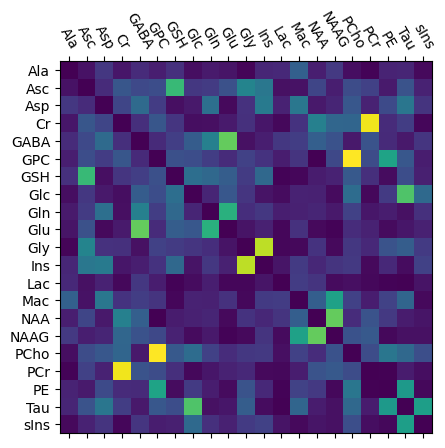

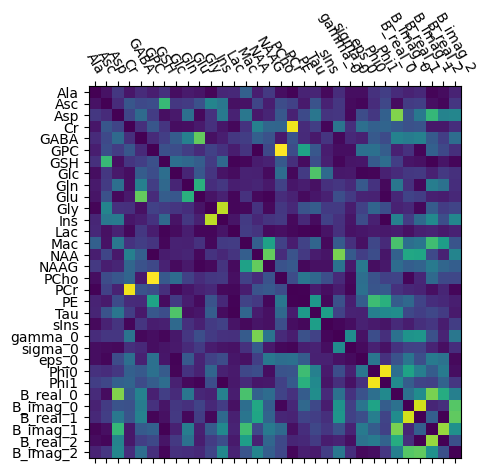

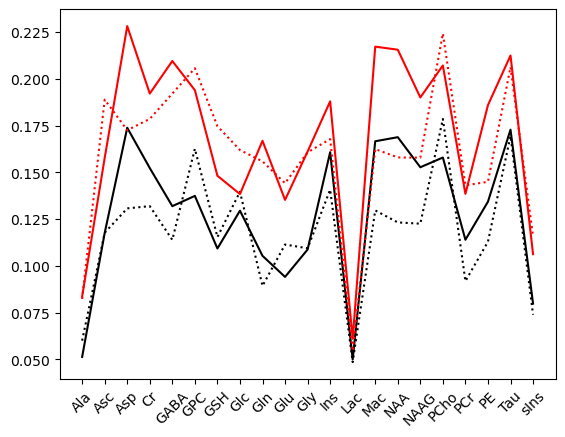

In [270]:
om_len = len(res.original_metabs)
mean_corr_mat_11_diag = mean_corr_mat_11 - np.diag(np.diag(mean_corr_mat_11))
mean_corr_mat_23_diag = mean_corr_mat_23 - np.diag(np.diag(mean_corr_mat_23))

metab_corr_11 = mean_corr_mat_11_diag[:om_len, :om_len]
metab_corr_23 = mean_corr_mat_23_diag[:om_len, :om_len]

plt.matshow(np.abs(metab_corr_23))
plt.xticks(ticks=np.arange(om_len), labels=res.original_metabs, rotation = -60)
plt.yticks(ticks=np.arange(om_len), labels=res.original_metabs)
plt.show()

plt.matshow(np.abs(mean_corr_mat_23_diag))
plt.xticks(ticks=np.arange(mean_corr_mat_23_diag.shape[0]), labels=res.params_names, rotation = -60)
plt.yticks(ticks=np.arange(mean_corr_mat_23_diag.shape[0]), labels=res.params_names)
plt.show()

mean_corr_metab_11 = np.mean(np.abs(metab_corr_11),axis=0)
mean_corr_11 = np.mean(np.abs(mean_corr_mat_11_diag),axis=0)[:om_len]

mean_corr_metab_23 = np.mean(np.abs(metab_corr_23),axis=0)
mean_corr_23 = np.mean(np.abs(mean_corr_mat_23_diag),axis=0)[:om_len]

plt.plot(mean_corr_11, 'k')
plt.plot(mean_corr_metab_11, 'k:')
plt.plot(mean_corr_23, 'r')
plt.plot(mean_corr_metab_23, 'r:')
plt.xticks(ticks=np.arange(om_len), labels=res.original_metabs, rotation = 45)
plt.show()

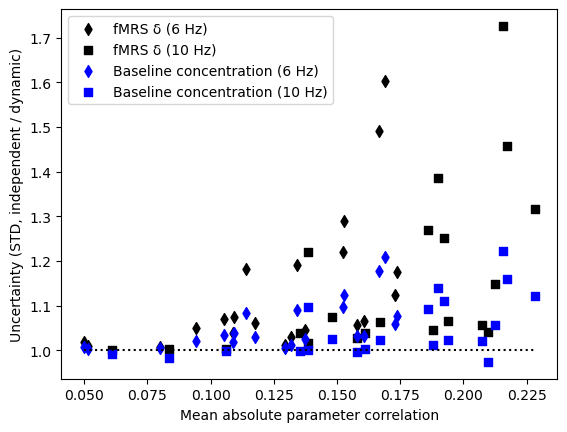

In [239]:
ratios_beta0_11 = ratios_beta0.groupby(level=[1]).mean().loc[11.0,:]
ratios_beta0_23 = ratios_beta0.groupby(level=[1]).mean().loc[23.0,:]
ratios_beta1_11 = ratios_beta1.groupby(level=[1]).mean().loc[11.0,:]
ratios_beta1_23 = ratios_beta1.groupby(level=[1]).mean().loc[23.0,:]

plt.scatter(mean_corr_11, ratios_beta0_11.to_numpy(), c='k', marker='d', label='fMRS δ (6 Hz)')
plt.scatter(mean_corr_23, ratios_beta0_23.to_numpy(), c='k', marker='s', label='fMRS δ (10 Hz)')
plt.scatter(mean_corr_11, ratios_beta1_11.to_numpy(), c='b', marker='d', label='Baseline concentration (6 Hz)')
plt.scatter(mean_corr_23, ratios_beta1_23.to_numpy(), c='b', marker='s', label='Baseline concentration (10 Hz)')
plt.hlines(1.0, xmin=0.05, xmax=mean_corr_23.max(), linestyles=':', colors='k')
plt.ylabel('Uncertainty (STD, independent / dynamic)')
plt.xlabel('Mean absolute parameter correlation')
plt.legend()
plt.show()